# LightGBM for IPL win probability


In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## 1. Load the data

This uses the same dataset and columns as the other notebooks. `match_id` is only used to keep deliveries from the same match together during validation; it isn't given to the model. The newer seasons are saved for a final check.

In [2]:
DATA_CANDIDATES = [
    Path("data/processed/reduced/Final_data.csv"),
    Path("../data/processed/reduced/Final_data.csv"),
]
DATA_PATH = next((p.resolve() for p in DATA_CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Can't find data/processed/reduced/Final_data.csv. "
        "Open the project folder in VS Code and check that the dataset is there."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows from {DATA_PATH}")
print(f"Matches: {df['match_id'].nunique():,}")
print(f"Seasons: {df['season_id'].min()}–{df['season_id'].max()}")
df.head()

Loaded 117,558 rows from C:\Users\Lenovo\Documents\IPL ML\data\processed\reduced\Final_data.csv
Matches: 1,063
Seasons: 2008–2026


,match_id,team_batting,team_bowling,current_score,season_id,match_date,city,venue,target_runs,runs_left,CRR,balls_left,RRR,wickets_left,runs_last_30,wickets_last_30,won
0,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,1,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,222,6.0,119,11.193277,10,1.0,0.0,0
1,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,2,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,221,6.0,118,11.237288,10,2.0,0.0,0
2,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,3,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,220,6.0,117,11.282051,10,3.0,0.0,0
3,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,4,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,219,6.0,116,11.327586,10,4.0,0.0,0
4,335982,Royal Challengers Bengaluru,Kolkata Knight Riders,4,2008,2008-04-18,Bangalore,"M Chinnaswamy Stadium, Bengaluru",223,219,4.8,115,11.426087,10,4.0,0.0,0


In [3]:
FEATURES = [
    "target_runs",
    "runs_left",
    "CRR",
    "balls_left",
    "RRR",
    "wickets_left",
]
TARGET = "won"
GROUP = "match_id"

needed = FEATURES + [TARGET, GROUP, "season_id"]
assert df[needed].notna().all().all(), "Some required columns have missing values."
assert set(df[TARGET].unique()).issubset({0, 1}), "The target should contain 0 and 1 only."
assert not (df.groupby(GROUP)[TARGET].nunique() > 1).any(), "A match has more than one outcome label."

dev = df.loc[df["season_id"] <= 2024].copy().reset_index(drop=True)
test = df.loc[df["season_id"] >= 2025].copy().reset_index(drop=True)
assert not dev.empty and not test.empty, "Need development seasons through 2024 and a 2025+ holdout."
assert set(dev[GROUP]).isdisjoint(set(test[GROUP])), "A match appears in both development and holdout data."

X_dev = dev[FEATURES]
y_dev = dev[TARGET].astype(int)
groups_dev = dev[GROUP]
X_test = test[FEATURES]
y_test = test[TARGET].astype(int)

print(f"Development: {len(dev):,} rows across {groups_dev.nunique():,} matches (through 2024)")
print(f"Later-season holdout: {len(test):,} rows across {test[GROUP].nunique():,} matches (2025 onward)")
if "match_date" in test.columns:
    print("Latest date in holdout:", test["match_date"].max())

Development: 105,663 rows across 953 matches (through 2024)
Later-season holdout: 11,895 rows across 110 matches (2025 onward)
Latest date in holdout: 2026-05-01


## 2. Set up the models

These LightGBM settings are just a starting point, not the result of a big tuning search. `n_estimators` is the number of trees, `num_leaves` controls how many end-points a tree can have, and `learning_rate` controls how much each new tree adjusts the model.

LightGBM doesn't need feature scaling. Logistic Regression does, so its scaler stays inside a pipeline.

In [4]:
def make_model(name):
    if name == "Logistic Regression":
        return Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000)),
        ])

    if name == "LightGBM":
        return LGBMClassifier(
            objective="binary",
            n_estimators=300,
            learning_rate=0.05,
            num_leaves=15,
            max_depth=5,
            min_child_samples=100,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            reg_lambda=5,
            importance_type="gain",
            n_jobs=-1,
            random_state=42,
        )

    raise ValueError(f"Unknown model: {name}")

MODEL_NAMES = ["Logistic Regression", "LightGBM"]

## 3. Compare them on grouped folds

We'll use five folds from the development seasons. Rows from one match stay together, so deliveries from the same match won't appear in both the training and validation parts of a fold.

Log loss and Brier score measure probability errors (lower is better). ROC-AUC and accuracy are also included (higher is better).

In [5]:
def score_model(y_true, probabilities):
    return {
        "log_loss": log_loss(y_true, probabilities, labels=[0, 1]),
        "brier": brier_score_loss(y_true, probabilities),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "accuracy": accuracy_score(y_true, probabilities >= 0.5),
    }

cv = GroupKFold(n_splits=5)
cv_rows = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_dev, y_dev, groups_dev), start=1
):
    train_matches = set(groups_dev.iloc[train_idx])
    val_matches = set(groups_dev.iloc[val_idx])
    assert train_matches.isdisjoint(val_matches), "A match leaked across a CV fold."

    X_train, X_val = X_dev.iloc[train_idx], X_dev.iloc[val_idx]
    y_train, y_val = y_dev.iloc[train_idx], y_dev.iloc[val_idx]

    for name in MODEL_NAMES:
        start = time.time()
        model = make_model(name)
        model.fit(X_train, y_train)
        p_val = model.predict_proba(X_val)[:, 1]

        row = {"model": name, "fold": fold, **score_model(y_val, p_val)}
        row["fit_seconds"] = time.time() - start
        cv_rows.append(row)
        print(f"Fold {fold}/5 | {name}: log loss = {row['log_loss']:.4f}")

cv_results = pd.DataFrame(cv_rows)
cv_summary = (
    cv_results.groupby("model")
    .agg(
        log_loss_mean=("log_loss", "mean"),
        log_loss_std=("log_loss", "std"),
        brier_mean=("brier", "mean"),
        roc_auc_mean=("roc_auc", "mean"),
        accuracy_mean=("accuracy", "mean"),
        total_fit_seconds=("fit_seconds", "sum"),
    )
    .sort_values("log_loss_mean")
)

display(cv_summary.round(4))

Fold 1/5 | Logistic Regression: log loss = 0.4273
[LightGBM] [Info] Number of positive: 42833, number of negative: 41719
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000497 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1046
[LightGBM] [Info] Number of data points in the train set: 84552, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.506588 -> initscore=0.026352
[LightGBM] [Info] Start training from score 0.026352
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning]

,log_loss_mean,log_loss_std,brier_mean,roc_auc_mean,accuracy_mean,total_fit_seconds
model,,,,,,
Logistic Regression,0.4405,0.025,0.1454,0.8744,0.7839,0.4360
LightGBM,0.4843,0.035,0.1575,0.8549,0.7633,2.2583


## 4. Check the newer seasons

Now train each model on all development seasons and check it on seasons from 2025 onward. Keep this as a final check; don't keep changing LightGBM settings just to improve this score. The 2026 season in this dataset is only partial.

In [6]:
holdout_rows = []
trained_models = {}

for name in MODEL_NAMES:
    model = make_model(name)
    model.fit(X_dev, y_dev)
    p_test = model.predict_proba(X_test)[:, 1]

    row = {"model": name, **score_model(y_test, p_test)}
    holdout_rows.append(row)
    trained_models[name] = model

holdout_results = (
    pd.DataFrame(holdout_rows)
    .set_index("model")
    .sort_values("log_loss")
)
display(holdout_results.round(4))

[LightGBM] [Info] Number of positive: 54189, number of negative: 51474
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000610 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1054
[LightGBM] [Info] Number of data points in the train set: 105663, number of used features: 6
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.512847 -> initscore=0.051401
[LightGBM] [Info] Start training from score 0.051401
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

,log_loss,brier,roc_auc,accuracy
model,,,,
Logistic Regression,0.4244,0.1391,0.9001,0.7935
LightGBM,0.6613,0.1958,0.8367,0.7451


## 5. Which features mattered to LightGBM?

This chart uses LightGBM's gain-based importance: how much the model's splits improved its objective in total for each feature. It's a useful rough guide, but it doesn't prove that a feature causes a win.

,feature,importance
0,RRR,308145.7710
1,target_runs,156065.7397
2,wickets_left,53245.9329
3,runs_left,45022.9064
4,CRR,29632.2817
5,balls_left,6638.6976


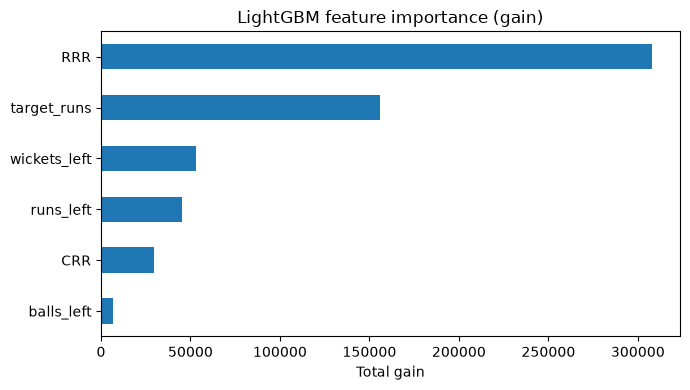

In [7]:
lgbm_model = trained_models["LightGBM"]
feature_importance = (
    pd.DataFrame({
        "feature": FEATURES,
        "importance": lgbm_model.feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.round(4))
feature_importance.sort_values("importance").plot(
    kind="barh", x="feature", y="importance", legend=False, figsize=(7, 4)
)
plt.title("LightGBM feature importance (gain)")
plt.xlabel("Total gain")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 6. Save the results

These reports let us bring the LightGBM results into the model comparison later. The dataset itself stays where it is.

In [8]:
# Find the project folder whether the notebook was opened from the root or models/.
ROOT_CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p.resolve() for p in ROOT_CANDIDATES if (p / ".git").exists()),
    Path.cwd().resolve(),
)
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

cv_results.to_csv(REPORT_DIR / "lightgbm_grouped_cv_folds.csv", index=False)
cv_summary.to_csv(REPORT_DIR / "lightgbm_grouped_cv_summary.csv")
holdout_results.to_csv(REPORT_DIR / "lightgbm_temporal_holdout.csv")
feature_importance.to_csv(REPORT_DIR / "lightgbm_feature_importance.csv", index=False)

print(f"Saved four reports to: {REPORT_DIR}")

Saved four reports to: C:\Users\Lenovo\Documents\IPL ML\reports
